#Тема 2. Моделирование связи частотного и классического определения вероятности
Приведите пример, показывающий связь частотного и классического определения вероятности с помощью моделирования (на примере задачи про красно-синие шары или задачи о сумме очков на двух кубиках). Графически показать стремление частотной вероятности к классической при увеличении числа опытов.

Для рассмотрения связи частотного и классического определения вероятности будет взята следующая задача:

Из колоды в 36 карт наудачу извлекются 4 карты. Найти вероятность того, что среди извлеченных карт представлены все "картинки" (туз, король, дама, валет).



## Классическое определение вероятности
Согласно классическому определению вероятность события $A$ равна отношению числа случаев, благоприятствующим ему, к общему числу случаев, т.е.

$$P(A)=\dfrac{m}{n}$$, где

* $P(A)$ - вероятность события $A$;

* $m$ - число случаев, благоприятствующих событию $A$;

* $n$ - общее число случаев.

Таким образом, для нахождения классической вероятности в данной задаче необходимо определить общее число исходов и благоприятное. К общему числу исходов отнесем все возможные сочетания 4-ех случайных карт, вытянутых из колоды с 36 картами - $C_{36}^4$. Число благоприятных исходов определяется исходя из количества карт с картинками. Стоит отметить, что просто вытянуть 4 карты из 16 возможных "картинок" мы не можем, поскольку по условию они не должны повторяться. Следовательно, стоит посчитать все возможные варианты вытянуть 1 карту определенного номинала из 4ех карт того же номинала, но разных мастей - $C_4^1$. Картинок всего 4, поэтому благоприятных случаев будет - $C_4^1 \cdot C_4^1 \cdot C_4^1 \cdot C_4^1$.
Тогда,

$P(A) = \dfrac{C_4^1 \cdot C_4^1 \cdot C_4^1 \cdot C_4^1}{C_{36}^4}$

Смоделируем решение данной задачи при помощи кода:

In [1]:
from scipy.special import comb

print(round(comb(4, 1)*comb(4, 1)*comb(4, 1)*comb(4, 1)/comb(36, 4), 4))

0.0043


## Частотное определение вероятности

Вычисление вероятности построено на эксперименте, который проводится $N$ раз ($N \rightarrow \infty$), а вероятность события $A$ определяется как отношение $N_A$ - количества исходов, когда событие $A$ произошло к $N$ при $N \rightarrow \infty$:

$$P(A) = \lim_{N \to \infty} \dfrac{N_A}{N}$$


Чтобы подойти к решению задачу со стороны частотного подхода, достаточно определенное количество раз $N$ вытягивать 4 карты из 36-ти доступных и затем посмотреть, сколько из них было вариантов с 4-мя неповторяющимися картинками.

Смоделируем эти действия при помощи кода:

In [3]:
from random import sample

N = 100000 # количество экспериментов

# П - пики
# Ч - червы
# Б - бубны
# Т - трефы

suits = ['П', 'Ч', 'Б', 'Т']
nums = ['6', '7', '8', '9', '10', 'В', 'Д', 'К', 'Т']
target = {'В', 'Д', 'К', 'Т'}

cards = [(num, suit) for suit in suits for num in nums]

pos = 0
med = []
for i in range(N):
  example = sample(cards, 4)
  # использую множество, чтобы сразу избавиться от случая с повторяющимися номиналами
  nums_of_cards = {card[0] for card in example}
  ok = nums_of_cards == target
  if ok:
    pos += 1
  if i % 100 == 0:
    med.append(pos/(i+1))









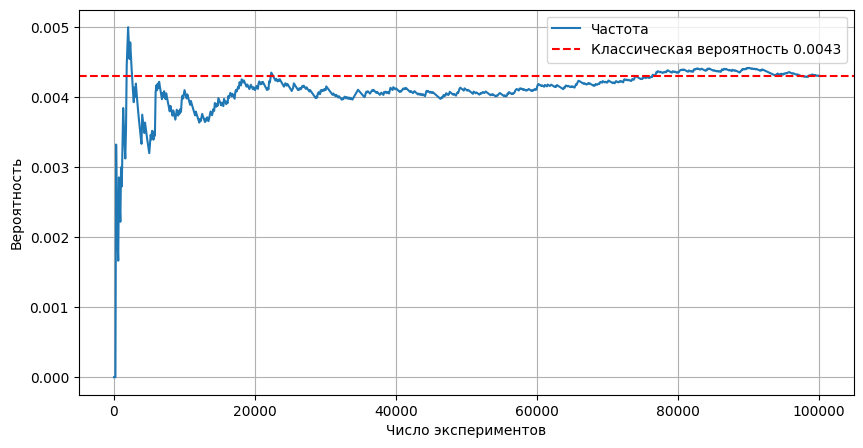

In [4]:
import matplotlib.pyplot as plt

from scipy.special import comb

P = round(comb(4, 1)*comb(4, 1)*comb(4, 1)*comb(4, 1)/comb(36, 4), 4) # классическая
x = range(1, N+1, 100) # где считалась частота


plt.figure(figsize=(10, 5))
plt.plot(x, med, label='Частота')
plt.axhline(P, color='red', linestyle='--', label=f'Классическая вероятность {P}')
plt.xlabel('Число экспериментов')
plt.ylabel('Вероятность')
plt.legend()
plt.grid()
plt.show()



Таким образом, можно заметить, как при увеличении числа экспериментов вероятность сходится к значению, вычисленному классическим подходом.